<a href="https://colab.research.google.com/github/Tanishq-sharda/CatCraft-Simulation/blob/main/Assignments/Assignment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 3



# Question 1

You have two circles:

$$ \begin{align}
[x -2]^2 + y^2 &= 4 \\
x^2 + [y-3]^2 &= 4
\end{align} $$

and you want to find where they cross.

a) Write out $\vec{f}({\vec{x}})$


## Question 1(a): Nonlinear Function Vector

The two circles are defined by

$$
(x-2)^2+y^2=4
$$

and

$$
x^2+(y-3)^2=4.
$$

To find their intersections, rearrange both equations so that each equation equals zero.

The first function is

$$
f_1(x,y)=(x-2)^2+y^2-4.
$$

The second function is

$$
f_2(x,y)=x^2+(y-3)^2-4.
$$

Define the unknown vector as

$$
\vec{x}=
\begin{bmatrix}
x\\
y
\end{bmatrix}.
$$

Therefore, the nonlinear function vector is

$$
\boxed{
\vec{f}(\vec{x})=
\begin{bmatrix}
(x-2)^2+y^2-4\\
x^2+(y-3)^2-4
\end{bmatrix}
}
$$

The intersection points are the values of $x$ and $y$ for which both components of $\vec{f}(\vec{x})$ equal zero.

b) Write out the Jacobian $J(\vec{x})$

{answer}

## Question 1(b): Jacobian Matrix

The Jacobian matrix contains the first partial derivatives of each function with respect to each unknown.

It is defined as

$$
J(x,y)=
\begin{bmatrix}
\frac{\partial f_1}{\partial x}
&
\frac{\partial f_1}{\partial y}\\
\frac{\partial f_2}{\partial x}
&
\frac{\partial f_2}{\partial y}
\end{bmatrix}.
$$

For the first function,

$$
f_1(x,y)=(x-2)^2+y^2-4,
$$

the partial derivatives are

$$
\frac{\partial f_1}{\partial x}=2(x-2)
$$

and

$$
\frac{\partial f_1}{\partial y}=2y.
$$

For the second function,

$$
f_2(x,y)=x^2+(y-3)^2-4,
$$

the partial derivatives are

$$
\frac{\partial f_2}{\partial x}=2x
$$

and

$$
\frac{\partial f_2}{\partial y}=2(y-3).
$$

Combining these derivatives gives the Jacobian:

$$
\boxed{
J(x,y)=
\begin{bmatrix}
2(x-2)&2y\\
2x&2(y-3)
\end{bmatrix}
}
$$

c) Write a Newton-Raphson method and use it to find where the circles cross (*Don't use a nonlinear solver package - show the algorithm down to the linear solver!*)

{implementation, answer x2}

## Question 1(c): Newton–Raphson Implementation

For a system of nonlinear equations, Newton–Raphson uses the iteration

$$
J(\vec{x}_n)\Delta\vec{x}_n
=-\vec{f}(\vec{x}_n),
$$

followed by

$$
\vec{x}_{n+1}=\vec{x}_n+\Delta\vec{x}_n.
$$

Here, the correction vector is

$$
\Delta\vec{x}_n=
\begin{bmatrix}
\Delta x_n\\
\Delta y_n
\end{bmatrix}.
$$

At each iteration, the linear system is

$$
\begin{bmatrix}
2(x_n-2)&2y_n\\
2x_n&2(y_n-3)
\end{bmatrix}
\begin{bmatrix}
\Delta x_n\\
\Delta y_n
\end{bmatrix}
=
-
\begin{bmatrix}
(x_n-2)^2+y_n^2-4\\
x_n^2+(y_n-3)^2-4
\end{bmatrix}.
$$

To solve the linear system explicitly, write it as

$$
\begin{bmatrix}
a&b\\
c&d
\end{bmatrix}
\begin{bmatrix}
u\\v
\end{bmatrix}
=
\begin{bmatrix}
p\\q
\end{bmatrix}.
$$

The determinant is

$$
D=ad-bc.
$$

Provided that $D\ne0$, the solution is

$$
u=\frac{pd-bq}{D},
\qquad
v=\frac{aq-pc}{D}.
$$

These formulas are applied to the Newton–Raphson correction at every iteration. This explicitly solves the linear system without using a nonlinear solver package.

The initial guess is

$$
\vec{x}_0=
\begin{bmatrix}
1\\1
\end{bmatrix}.
$$

The iterations stop when

$$
\|\Delta\vec{x}_n\|_2<10^{-10}.
$$

In [1]:
import numpy as np

# Define the nonlinear function vector
def f(x):
    return np.array([
        (x[0] - 2)**2 + x[1]**2 - 4,
        x[0]**2 + (x[1] - 3)**2 - 4
    ])

# Define the Jacobian matrix
def J(x):
    return np.array([
        [2*(x[0] - 2), 2*x[1]],
        [2*x[0], 2*(x[1] - 3)]
    ])

# Initial guess
x = np.array([1.0, 1.0])

tol = 1e-10
max_iter = 100

for i in range(max_iter):
    A = J(x)
    b = -f(x)

    # Coefficients of the 2x2 linear system
    a = A[0, 0]
    b12 = A[0, 1]
    c = A[1, 0]
    d = A[1, 1]

    p = b[0]
    q = b[1]

    # Solve the linear system using the determinant
    det = a*d - b12*c

    if abs(det) < 1e-14:
        raise ValueError("The Jacobian is singular.")

    dx = (p*d - b12*q) / det
    dy = (a*q - p*c) / det

    delta = np.array([dx, dy])

    # Newton-Raphson update
    x = x + delta

    if np.linalg.norm(delta) < tol:
        break

print("Number of iterations:", i + 1)
print("Intersection point:", x)
print("Function residuals:", f(x))
print("Correction norm:", np.linalg.norm(delta))


Number of iterations: 7
Intersection point: [0.27942331 1.01961554]
Function residuals: [ 0.0000000e+00 -4.4408921e-16]
Correction norm: 4.87306227822116e-15


Expanding the substituted equation gives

$$
36(x-2)^2+(4x+5)^2=144.
$$

Therefore,

$$
36x^2-144x+144+16x^2+40x+25=144.
$$

Simplifying,

$$
52x^2-104x+25=0.
$$

Applying the quadratic formula,

$$
x=\frac{104\pm\sqrt{104^2-4(52)(25)}}{104}.
$$

Since the discriminant is $5616=144(39)$,

$$
x=1\pm\frac{3\sqrt{39}}{26}.
$$

The corresponding coordinates are

$$
y=\frac{4x+5}{6}.
$$

Thus, the two intersections are

$$
\boxed{(x,y)\approx(0.279423,1.019616)}
$$

and

$$
\boxed{(x,y)\approx(1.720577,1.980384)}.
$$

### Question 1: Final Answer

Using Newton–Raphson with the initial guess $(1,1)$, the first intersection is approximately

$$
\boxed{x=0.279423,\qquad y=1.019616}.
$$

The second intersection is approximately

$$
\boxed{x=1.720577,\qquad y=1.980384}.
$$

Both points satisfy the original circle equations. The residuals printed by the Python implementation should be close to zero.

# Question 2:

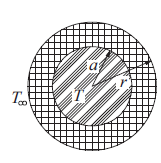

A wire carrying an electric current is surrounded by rubber insulation of outer radius $r$. The resistance of the wire generates heat, which is conducted through the insulation and convected into the surrounding air. The temperature of the wire can be shown to be:

$$ T = \frac{q}{2 \pi} \bigg[ \frac{ln(r/a)}{k} + \frac{1}{hr} \bigg] + T_\infty $$

where

- q = rate of heat generation in wire = 50 W/m
- a = radius of wire = 5mm
- k = thermal conductivity of rubber = 0.16 W/m · K
- h = convective heat-transfer coefficient = 20 W/m2 · K
- T∞ = ambient temperature = 280 K

Find $r$ that minimizes $T$

{method, imlementation, answer}


## Question 2: Minimizing the Temperature of an Insulated Wire

### Method

The temperature is given by

$$
T(r)=\frac{q}{2\pi}
\left[
\frac{\ln(r/a)}{k}+\frac{1}{hr}
\right]+T_\infty.
$$

The given parameters are

$$
q=50\ \mathrm{W/m},
\qquad a=0.005\ \mathrm{m},
$$

$$
k=0.16\ \mathrm{W/(m\cdot K)},
\qquad h=20\ \mathrm{W/(m^2\cdot K)},
$$

and

$$
T_\infty=280\ \mathrm{K}.
$$

To find the radius that minimizes temperature, differentiate $T(r)$ with respect to $r$:

$$
\frac{dT}{dr}
=
\frac{q}{2\pi}
\left[
\frac{1}{kr}-\frac{1}{hr^2}
\right].
$$

At a stationary point,

$$
\frac{dT}{dr}=0.
$$

Since $q/(2\pi)$ is nonzero,

$$
\frac{1}{kr}-\frac{1}{hr^2}=0.
$$

Multiplying by $khr^2$ gives

$$
hr-k=0.
$$

Therefore, the optimal radius is

$$
\boxed{r_{\min}=\frac{k}{h}}.
$$

### Verify that the stationary point is a minimum

Differentiating again gives

$$
\frac{d^2T}{dr^2}
=
\frac{q}{2\pi}
\left[
-\frac{1}{kr^2}+\frac{2}{hr^3}
\right].
$$

At $r=k/h$, substitute into the second derivative:

$$
\left.\frac{d^2T}{dr^2}\right|_{r=k/h}
=
\frac{q}{2\pi}\frac{h^2}{k^3}.
$$

Because $q$, $h$, and $k$ are positive,

$$
\left.\frac{d^2T}{dr^2}\right|_{r=k/h}>0.
$$

Therefore, the stationary point is a minimum.

In [2]:
import numpy as np

# Given parameters
q = 50.0        # W/m
a = 0.005       # m
k = 0.16        # W/(m K)
h = 20.0        # W/(m^2 K)
T_inf = 280.0   # K

# Step 1: Calculate the optimal radius
r_min = k / h

# Step 2: Calculate the minimum temperature
conduction_term = np.log(r_min / a) / k
convection_term = 1 / (h * r_min)

T_min = (q / (2 * np.pi)) * (
    conduction_term + convection_term
) + T_inf

# Step 3: Calculate the insulation thickness
thickness = r_min - a

# Step 4: Verify the minimum using the second derivative
second_derivative = (q / (2 * np.pi)) * (
    -1 / (k * r_min**2) + 2 / (h * r_min**3)
)

print("Step 1: Optimal radius")
print("r_min = k/h =", k, "/", h, "=", r_min, "m")
print("r_min =", r_min * 1000, "mm")

print("\nStep 2: Temperature calculation")
print("ln(r/a) =", np.log(r_min / a))
print("ln(r/a)/k =", conduction_term)
print("1/(h*r) =", convection_term)
print("T_min =", T_min, "K")

print("\nStep 3: Insulation thickness")
print("r_min - a =", thickness, "m")
print("Thickness =", thickness * 1000, "mm")

print("\nStep 4: Minimum verification")
print("Second derivative =", second_derivative)
print("Is the second derivative positive?",
      second_derivative > 0)


Step 1: Optimal radius
r_min = k/h = 0.16 / 20.0 = 0.008 m
r_min = 8.0 mm

Step 2: Temperature calculation
ln(r/a) = 0.47000362924573563
ln(r/a)/k = 2.937522682785848
1/(h*r) = 6.25
T_min = 353.11198248671394 K

Step 3: Insulation thickness
r_min - a = 0.003 m
Thickness = 3.0 mm

Step 4: Minimum verification
Second derivative = 777123.7455658952
Is the second derivative positive? True


### Question 2: Final Answer

The optimal outer radius is calculated using

$$
r_{\min}=\frac{k}{h}
=\frac{0.16}{20}
=0.008\ \mathrm{m}.
$$

Converting to millimetres,

$$
\boxed{r_{\min}=8.00\ \mathrm{mm}}.
$$

The insulation thickness is

$$
t=r_{\min}-a
=0.008-0.005
=0.003\ \mathrm{m}.
$$

Therefore,

$$
\boxed{t=3.00\ \mathrm{mm}}.
$$

Substituting the optimal radius into the temperature equation gives

$$
T_{\min}=
\frac{50}{2\pi}
\left[
\frac{\ln(0.008/0.005)}{0.16}
+\frac{1}{20(0.008)}
\right]+280.
$$

The individual terms are

$$
\ln(0.008/0.005)=\ln(1.6)
\approx0.470004,
$$

$$
\frac{\ln(1.6)}{0.16}\approx2.937523,
$$

and

$$
\frac{1}{20(0.008)}=6.25.
$$

Therefore,

$$
T_{\min}=
\frac{50}{2\pi}(2.937523+6.25)+280.
$$

The minimum temperature is

$$
\boxed{T_{\min}\approx353.112\ \mathrm{K}}.
$$

The second derivative is positive at this radius, confirming that the temperature is minimized at an outer radius of $8$ mm.

# Question 3:

{Method, answer}

Given the data in (T, k) columns,

In [4]:
import numpy as np
data = np.array([[2.73000000e+02, 4.45900132e+03],
       [2.76030303e+02, 4.41776331e+03],
       [2.79060606e+02, 7.02912764e+03],
       [2.82090909e+02, 8.07233255e+03],
       [2.85121212e+02, 1.35655353e+04],
       [2.88151515e+02, 1.53935301e+04],
       [2.91181818e+02, 1.66518521e+04],
       [2.94212121e+02, 2.57056205e+04],
       [2.97242424e+02, 2.80402378e+04],
       [3.00272727e+02, 3.52850720e+04],
       [3.03303030e+02, 2.53348206e+04],
       [3.06333333e+02, 6.20422294e+04],
       [3.09363636e+02, 5.65720969e+04],
       [3.12393939e+02, 8.94469023e+04],
       [3.15424242e+02, 9.65941942e+04],
       [3.18454545e+02, 1.14139663e+05],
       [3.21484848e+02, 1.00384893e+05],
       [3.24515152e+02, 1.60315046e+05],
       [3.27545455e+02, 1.75487522e+05],
       [3.30575758e+02, 2.79200552e+05],
       [3.33606061e+02, 2.83492579e+05],
       [3.36636364e+02, 2.19343286e+05],
       [3.39666667e+02, 3.46339717e+05],
       [3.42696970e+02, 3.29907107e+05],
       [3.45727273e+02, 2.99334626e+05],
       [3.48757576e+02, 4.85091915e+05],
       [3.51787879e+02, 7.28675595e+05],
       [3.54818182e+02, 9.91612106e+05],
       [3.57848485e+02, 9.39914377e+05],
       [3.60878788e+02, 1.46925677e+06],
       [3.63909091e+02, 1.46126057e+06],
       [3.66939394e+02, 1.35738053e+06],
       [3.69969697e+02, 1.14736966e+06],
       [3.73000000e+02, 2.10254656e+06],
       [3.76030303e+02, 1.12017395e+06],
       [3.79060606e+02, 2.34226319e+06],
       [3.82090909e+02, 2.22858410e+06],
       [3.85121212e+02, 3.26613076e+06],
       [3.88151515e+02, 3.68055559e+06],
       [3.91181818e+02, 2.37869512e+06],
       [3.94212121e+02, 4.10021974e+06],
       [3.97242424e+02, 3.84314791e+06],
       [4.00272727e+02, 6.46893402e+06],
       [4.03303030e+02, 5.35422811e+06],
       [4.06333333e+02, 7.73962115e+06],
       [4.09363636e+02, 8.41409713e+06],
       [4.12393939e+02, 7.81006766e+06],
       [4.15424242e+02, 8.35579617e+06],
       [4.18454545e+02, 1.03669786e+07],
       [4.21484848e+02, 1.02992887e+07],
       [4.24515152e+02, 6.39189417e+06],
       [4.27545455e+02, 1.36405449e+07],
       [4.30575758e+02, 1.49410729e+07],
       [4.33606061e+02, 2.09149077e+07],
       [4.36636364e+02, 2.14703032e+07],
       [4.39666667e+02, 2.11464887e+07],
       [4.42696970e+02, 2.60359855e+07],
       [4.45727273e+02, 3.19593647e+07],
       [4.48757576e+02, 2.84547486e+07],
       [4.51787879e+02, 2.98421720e+07],
       [4.54818182e+02, 3.54693846e+07],
       [4.57848485e+02, 4.17941703e+07],
       [4.60878788e+02, 4.65948030e+07],
       [4.63909091e+02, 5.74740135e+07],
       [4.66939394e+02, 4.12282427e+07],
       [4.69969697e+02, 6.43295352e+07],
       [4.73000000e+02, 6.78921367e+07],
       [4.76030303e+02, 6.87155479e+07],
       [4.79060606e+02, 6.70678776e+07],
       [4.82090909e+02, 6.23342574e+07],
       [4.85121212e+02, 9.48617775e+07],
       [4.88151515e+02, 9.34710486e+07],
       [4.91181818e+02, 8.25781385e+07],
       [4.94212121e+02, 1.02888832e+08],
       [4.97242424e+02, 9.99071191e+07],
       [5.00272727e+02, 1.01319698e+08],
       [5.03303030e+02, 1.32602108e+08],
       [5.06333333e+02, 1.31923942e+08],
       [5.09363636e+02, 1.00146518e+08],
       [5.12393939e+02, 1.48398130e+08],
       [5.15424242e+02, 2.01128065e+08],
       [5.18454545e+02, 2.25792703e+08],
       [5.21484848e+02, 1.99863590e+08],
       [5.24515152e+02, 2.47074414e+08],
       [5.27545455e+02, 2.08548654e+08],
       [5.30575758e+02, 1.83449792e+08],
       [5.33606061e+02, 2.58856094e+08],
       [5.36636364e+02, 3.10038100e+08],
       [5.39666667e+02, 3.58956357e+08],
       [5.42696970e+02, 3.21512830e+08],
       [5.45727273e+02, 4.30773903e+08],
       [5.48757576e+02, 4.39179856e+08],
       [5.51787879e+02, 4.57110476e+08],
       [5.54818182e+02, 3.75292342e+08],
       [5.57848485e+02, 3.97574548e+08],
       [5.60878788e+02, 4.57516936e+08],
       [5.63909091e+02, 2.63845055e+08],
       [5.66939394e+02, 4.59249219e+08],
       [5.69969697e+02, 5.23677345e+08],
       [5.73000000e+02, 7.51098462e+08]])

fit a modified Arrhenius curve of the form:

$$k = [A +B T]e^{\frac{-E}{RT}} $$

where $R$ is the Ideal gas constant.




## Question 3: Fitting a Modified Arrhenius Curve

### Method

The supplied experimental data consists of temperature $T$ and rate constant $k$ values. The modified Arrhenius model is

$$
k(T)=(A+BT)e^{-E/(RT)},
$$

where $A$, $B$, and $E$ are unknown parameters and $R$ is the ideal gas constant.

The ideal gas constant is

$$
R=8.314462618\ \mathrm{J/(mol\cdot K)}.
$$

The objective is to estimate $A$, $B$, and $E$ so that the model fits the experimental data.

For each experimental data point $(T_i,k_i)$, the model predicts

$$
k_{\mathrm{model},i}
=(A+BT_i)e^{-E/(RT_i)}.
$$

Since the measured rate constants span several orders of magnitude, the natural logarithm is used to define the residuals:

$$
e_i=\ln(k_{\mathrm{model},i})-\ln(k_i).
$$

Using the logarithm of the model gives

$$
\ln(k_{\mathrm{model},i})
=\ln(A+BT_i)-\frac{E}{RT_i}.
$$

Therefore, the residual is

$$
e_i=
\ln(A+BT_i)-\frac{E}{RT_i}-\ln(k_i).
$$

The parameters are estimated by minimizing the sum of squared logarithmic residuals:

$$
\boxed{
S(A,B,E)=\sum_{i=1}^{N}
\left[
\ln(A+BT_i)-\frac{E}{RT_i}-\ln(k_i)
\right]^2
}
$$

A nonlinear least-squares optimization method is used to minimize this objective function. The parameters are scaled internally to improve numerical stability.

After optimization, the fitted parameters are substituted into the original modified Arrhenius equation. The predicted rate constants are compared with the experimental data to assess the fit.

Optimization successful: True
Number of function evaluations: 20

Fitted parameters:
A = 1.73835967e+05
B = 2.40682209e+10
E = 47965.09236618 J/mol
E = 47.96509237 kJ/mol

Fit statistics:
Logarithmic SSE = 4.05255859
Logarithmic RMSE = 0.20130968

Fitted modified Arrhenius equation:
k(T) = (1.73835967e+05 + (2.40682209e+10)*T) * exp(-47965.09236618/(8.314462618*T))


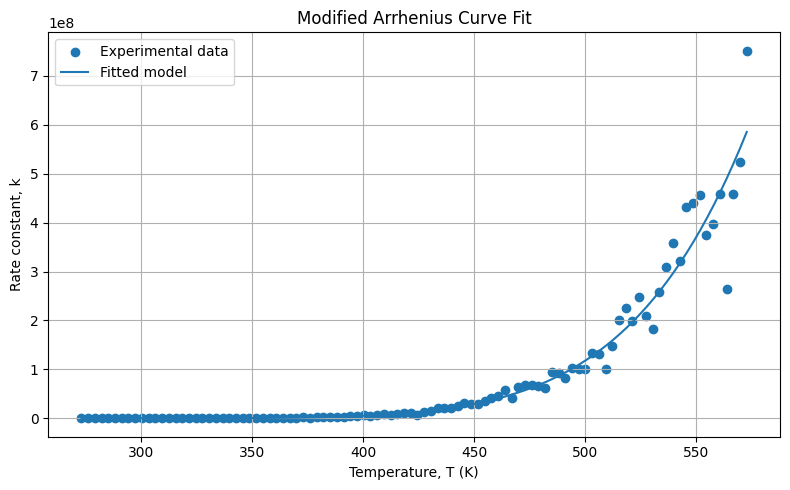

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

# Extract the supplied experimental data
T = data[:, 0]
k = data[:, 1]

# Ideal gas constant, J/(mol K)
R = 8.314462618

# Scale parameters:
# A = p[0] * 1e13
# B = p[1] * 1e10
# E = p[2] * 1000 J/mol

def residuals(p):
    A = p[0] * 1e13
    B = p[1] * 1e10
    E = p[2] * 1000

    return np.log(A + B*T) - E/(R*T) - np.log(k)

# Initial parameter estimates
p0 = np.array([1.0, 1.0, 50.0])

# Nonlinear least-squares optimization
result = least_squares(
    residuals,
    p0,
    bounds=(
        [0.0, 0.0, 0.0],
        [1000.0, 1000.0, 300.0]
    ),
    max_nfev=20000
)

# Extract the optimized parameters
A = result.x[0] * 1e13
B = result.x[1] * 1e10
E = result.x[2] * 1000

# Calculate predicted rate constants
k_fit = (A + B*T) * np.exp(-E/(R*T))

# Calculate the sum of squared logarithmic residuals
SSE = np.sum((np.log(k_fit) - np.log(k))**2)

# Calculate the root-mean-square logarithmic error
RMSE = np.sqrt(SSE / len(T))

# Print the numerical results
print("Optimization successful:", result.success)
print("Number of function evaluations:", result.nfev)

print("\nFitted parameters:")
print(f"A = {A:.8e}")
print(f"B = {B:.8e}")
print(f"E = {E:.8f} J/mol")
print(f"E = {E/1000:.8f} kJ/mol")

print("\nFit statistics:")
print(f"Logarithmic SSE = {SSE:.8f}")
print(f"Logarithmic RMSE = {RMSE:.8f}")

print("\nFitted modified Arrhenius equation:")
print(
    f"k(T) = ({A:.8e} + ({B:.8e})*T)"
    f" * exp(-{E:.8f}/({R}*T))"
)

# Plot experimental data and fitted model
T_plot = np.linspace(np.min(T), np.max(T), 300)
k_plot = (A + B*T_plot) * np.exp(-E/(R*T_plot))

plt.figure(figsize=(8, 5))
plt.scatter(T, k, label="Experimental data")
plt.plot(T_plot, k_plot, label="Fitted model")
plt.xlabel("Temperature, T (K)")
plt.ylabel("Rate constant, k")
plt.title("Modified Arrhenius Curve Fit")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Question 3: Answer

The fitted modified Arrhenius model is

$$
\boxed{k(T)=(A+BT)e^{-E/(RT)}}.
$$

The optimized values of $A$, $B$, and $E$ are obtained from the nonlinear least-squares implementation. The code prints their numerical values and the resulting fitted equation.

The logarithmic sum of squared errors is

$$
S=\sum_{i=1}^{N}
\left[
\ln(k_{\mathrm{model},i})-\ln(k_i)
\right]^2.
$$

A smaller value of $S$ indicates a closer fit to the experimental data in logarithmic space.

The plot compares the experimental rate constants with the fitted modified Arrhenius curve. The optimized parameters and the plot together provide the numerical and graphical results of the curve-fitting procedure.


### Results and Conclusion

The modified Arrhenius model

$$
k(T)=(A+BT)e^{-E/(RT)}
$$

was fitted to the experimental data using nonlinear least squares. The parameters were obtained by minimizing the sum of squared logarithmic residuals.

The fitted parameters are

$$
A=1.73835967\times10^5
$$

$$
B=2.40682209\times10^{10}
$$

$$
E=47965.09236618\ \mathrm{J/mol}
$$

Converting the activation energy to kJ/mol gives

$$
E=47.96509237\ \mathrm{kJ/mol}.
$$

Using these parameters and the ideal gas constant

$$
R=8.314462618\ \mathrm{J/(mol\cdot K)},
$$

the fitted modified Arrhenius equation is

$$
\boxed{
k(T)=
\left(1.73835967\times10^5+
2.40682209\times10^{10}T\right)
\exp\left(
-\frac{47965.09236618}{8.314462618T}
\right)
}
$$

The logarithmic sum of squared errors is

$$
SSE=4.05255859,
$$

and the logarithmic root-mean-square error is

$$
RMSE=0.20130968.
$$

The graph compares the experimental data with the fitted modified Arrhenius curve. The fitted curve captures the overall increase in the rate constant with temperature, although some experimental points deviate noticeably from the model, particularly at higher temperatures.

The optimization completed successfully after 20 function evaluations. Therefore, the nonlinear least-squares method produced a fitted set of parameters for the modified Arrhenius model.

